# Imports

In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import os


In [2]:
# Tự động kiểm tra file dữ liệu trên Google Colab / máy cục bộ
# Nếu chưa có file gốc user1_data.csv và user2_data.csv, hệ thống tự động sinh dataset mô phỏng.
user1_path = '/content/user1_data.csv' if os.path.exists('/content') else 'user1_data.csv'
user2_path = '/content/user2_data.csv' if os.path.exists('/content') else 'user2_data.csv'

if not os.path.exists(user1_path) or not os.path.exists(user2_path):
    print('Không tìm thấy file dữ liệu gốc. Đang tự động sinh dataset mô phỏng (Synthetic Data)...')
    np.random.seed(42)
    n_samples = 6000
    start_date = pd.Timestamp('2022-07-18 00:00:00')
    time_series = [start_date + pd.Timedelta(minutes=5 * i) for i in range(n_samples)]

    hours = np.array([t.hour for t in time_series])
    daylight = np.maximum(0, np.sin((hours - 6) * np.pi / 12))

    temp = 18 + daylight * 13 + np.random.normal(0, 1.5, size=n_samples)
    humd = np.clip(92 - daylight * 38 + np.random.normal(0, 4, size=n_samples), 20, 100)
    pres = np.random.normal(93150, 200, size=n_samples)
    lum = daylight * np.random.uniform(5000, 18000, size=n_samples) + np.random.exponential(40, size=n_samples)
    st = 24 + 0.22 * (temp - 18) + np.random.normal(0, 0.4, size=n_samples)

    am = np.clip(np.random.gamma(2, 0.8, size=n_samples), 0, 18)
    pm1 = np.clip(np.random.normal(1.5, 0.7, size=n_samples), 0.5, 6.7)
    pm2 = np.clip(np.random.normal(2.5, 0.9, size=n_samples), 0.0, 6.7)
    pm3 = np.clip(np.random.normal(55, 18, size=n_samples), 0.0, 150.0)

    noise = np.random.normal(0, 60, size=n_samples)
    sm = 4200 + 38 * humd - 52 * temp - 45 * st - 0.04 * lum + 8 * am + noise
    sm = np.clip(sm, 200, 7900)

    ttime_str = [t.strftime('%Y-%m-%d %H:%M:%S') for t in time_series]

    synth_data1 = pd.DataFrame({
        'ttime': ttime_str,
        'pm1': np.clip(pm1 + np.random.normal(0, 0.05, n_samples), 0.5, 7.0),
        'pm2': np.clip(pm2 + np.random.normal(0, 0.05, n_samples), 0.0, 7.0),
        'pm3': np.clip(pm3 + np.random.normal(0, 0.5, n_samples), 0.0, 150.0),
        'am': am,
        'sm': sm,
        'st': st,
        'lum': lum
    })

    synth_data2 = pd.DataFrame({
        'ttime': ttime_str,
        'pm1': np.clip(pm1 + np.random.normal(0, 0.05, n_samples), 0.5, 7.0),
        'pm2': np.clip(pm2 + np.random.normal(0, 0.05, n_samples), 0.0, 7.0),
        'pm3': np.clip(pm3 + np.random.normal(0, 0.5, n_samples), 0.0, 150.0),
        'am': am,
        'sm': sm,
        'lum': lum,
        'temp': temp,
        'humd': humd,
        'pres': pres
    })

    synth_data1.loc[np.random.rand(n_samples) < 0.35, 'st'] = np.nan
    synth_data2.loc[np.random.rand(n_samples) < 0.30, ['temp', 'humd', 'pres']] = np.nan

    synth_data1.to_csv(user1_path, index=False)
    synth_data2.to_csv(user2_path, index=False)
    print('Sinh và lưu thành công data1 và data2 vào:', user1_path, user2_path)

data1 = pd.read_csv(user1_path)
data2 = pd.read_csv(user2_path)
print('Đã tải dữ liệu thành công! Kích thước data1:', data1.shape, '| data2:', data2.shape)


Không tìm thấy file dữ liệu gốc. Đang tự động sinh dataset mô phỏng (Synthetic Data)...
Sinh và lưu thành công data1 và data2 vào: /content/user1_data.csv /content/user2_data.csv
Đã tải dữ liệu thành công! Kích thước data1: (6000, 8) | data2: (6000, 10)


#Data Visualiztion

In [3]:
data1.columns

Index(['ttime', 'pm1', 'pm2', 'pm3', 'am', 'sm', 'st', 'lum'], dtype='object')

In [4]:
data1.shape

(6000, 8)

In [5]:
data2.columns

Index(['ttime', 'pm1', 'pm2', 'pm3', 'am', 'sm', 'lum', 'temp', 'humd',
       'pres'],
      dtype='object')

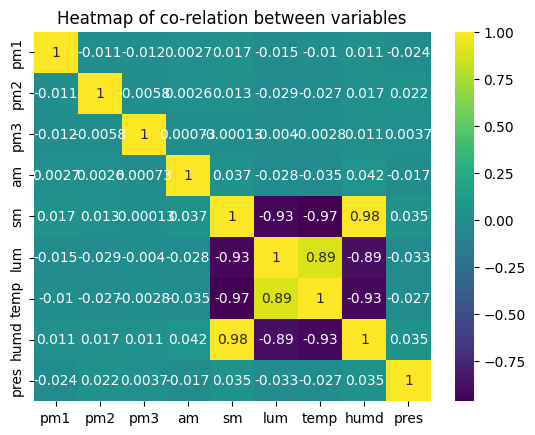

In [6]:
import seaborn as sns
import matplotlib.pyplot as plt

sns.heatmap(data2.corr(numeric_only=True), annot=True, cmap='viridis')
plt.title('Heatmap of co-relation between variables')
plt.show()

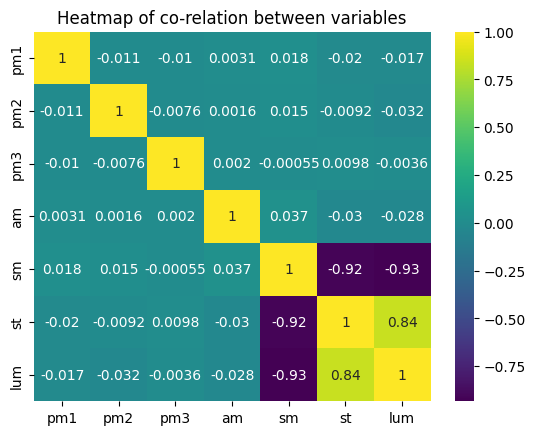

In [7]:
import seaborn as sns
import matplotlib.pyplot as plt

sns.heatmap(data1.corr(numeric_only=True), annot=True, cmap='viridis')
plt.title('Heatmap of co-relation between variables')
plt.show()

In [8]:
data1.tail()

,ttime,pm1,pm2,pm3,am,sm,st,lum
5995,2022-08-07 19:35:00,1.724874,4.095158,59.193362,2.477149,5483.295281,23.593071,37.833142
5996,2022-08-07 19:40:00,0.694107,2.805639,46.402015,1.619325,5460.653493,NaN,45.141333
5997,2022-08-07 19:45:00,0.742813,1.807432,43.704041,0.333698,5881.795913,22.941221,0.233509
5998,2022-08-07 19:50:00,0.839605,1.951071,57.753047,4.747320,5673.677098,NaN,27.633877
5999,2022-08-07 19:55:00,1.464760,2.437462,43.052214,3.649430,5671.708548,23.048577,22.566575


#Data Pre-Prosessing

In [9]:
data1['ttime']=pd.to_datetime(data1.ttime, format='%Y-%m-%d %H:%M:%S')
data1.set_index('ttime',inplace=True)
data1['day']=data1.index.day
data1['Month']=data1.index.month
data1['year']=data1.index.year
data1['hour']=data1.index.hour
data1['min']=(data1.index.minute//5)+1
data1.reset_index(inplace=True)
data1=data1.drop(['ttime'], axis=1)
data1

,pm1,pm2,pm3,am,sm,st,lum,day,Month,year,hour,min
0,1.475218,2.865306,66.878303,0.046249,5482.503651,23.821563,9.138662,18,7,2022,0,1
1,1.676730,3.643866,61.607716,1.748742,5628.854819,24.554918,47.365276,18,7,2022,0,2
2,1.610795,4.613143,55.383390,0.867783,5434.584234,NaN,0.124629,18,7,2022,0,3
3,2.721269,2.637204,42.152741,1.843684,5547.269207,NaN,31.831347,18,7,2022,0,4
4,2.466424,2.097824,49.527041,0.962695,5602.309998,23.749956,20.504264,18,7,2022,0,5
...,...,...,...,...,...,...,...,...,...,...,...,...
5995,1.724874,4.095158,59.193362,2.477149,5483.295281,23.593071,37.833142,7,8,2022,19,8
5996,0.694107,2.805639,46.402015,1.619325,5460.653493,NaN,45.141333,7,8,2022,19,9
5997,0.742813,1.807432,43.704041,0.333698,5881.795913,22.941221,0.233509,7,8,2022,19,10
5998,0.839605,1.951071,57.753047,4.747320,5673.677098,NaN,27.633877,7,8,2022,19,11


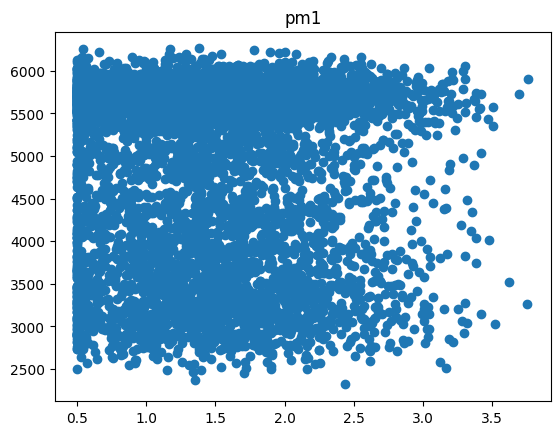

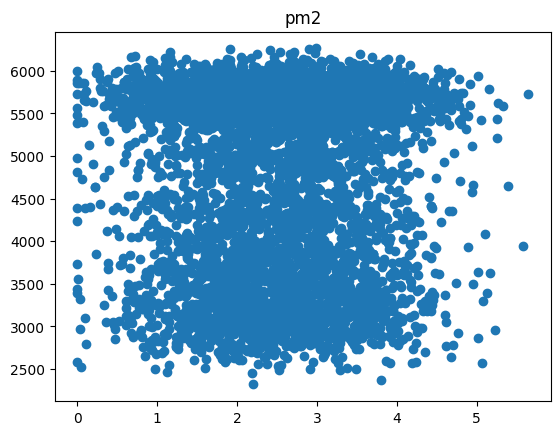

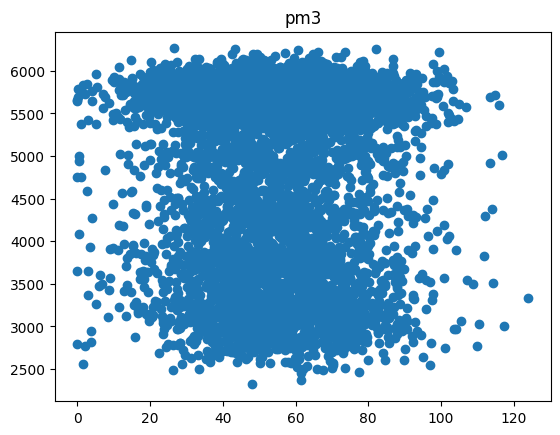

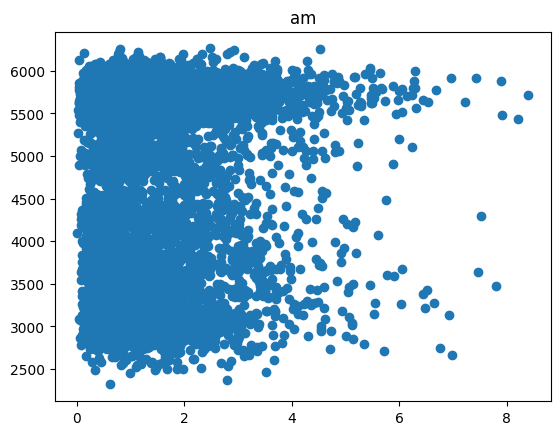

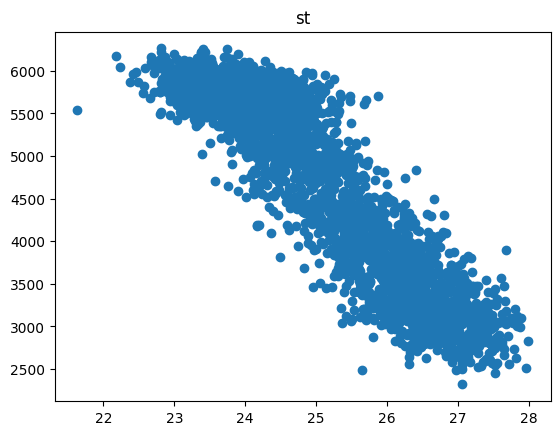

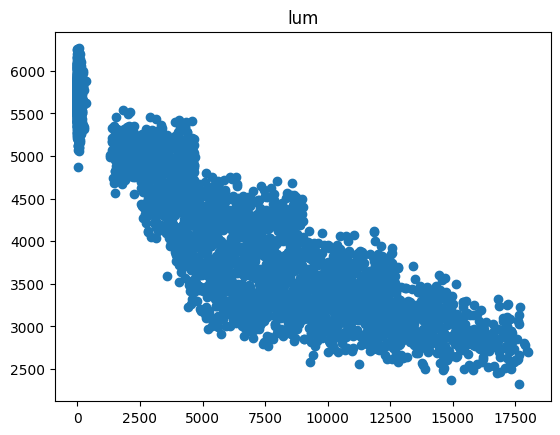

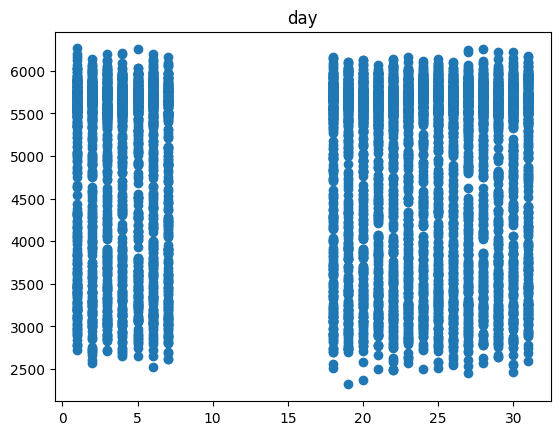

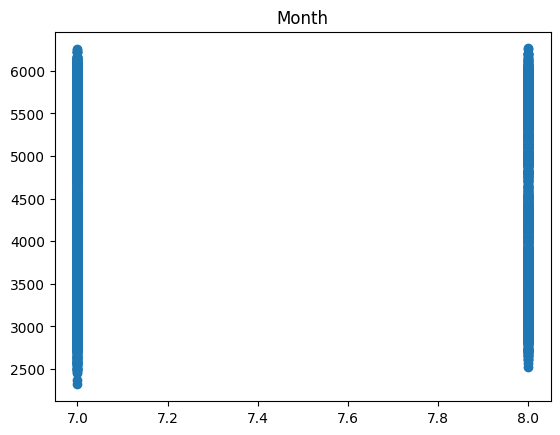

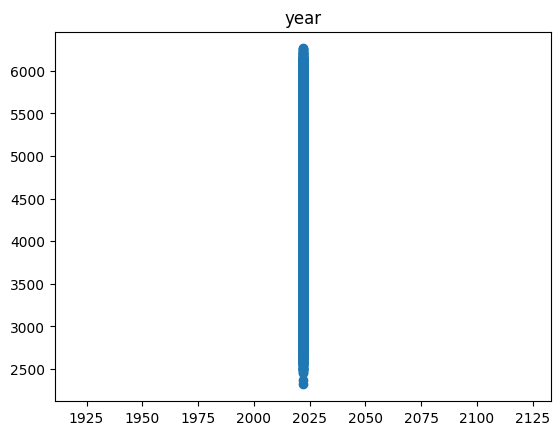

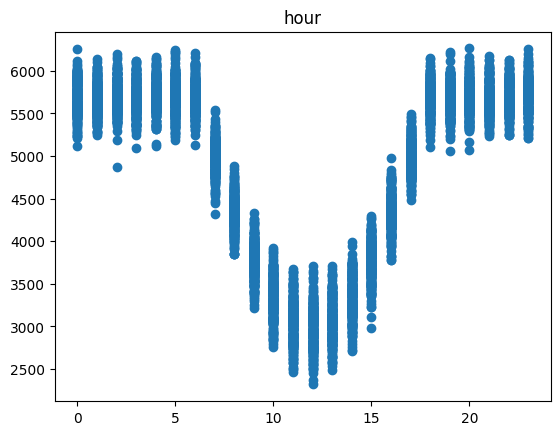

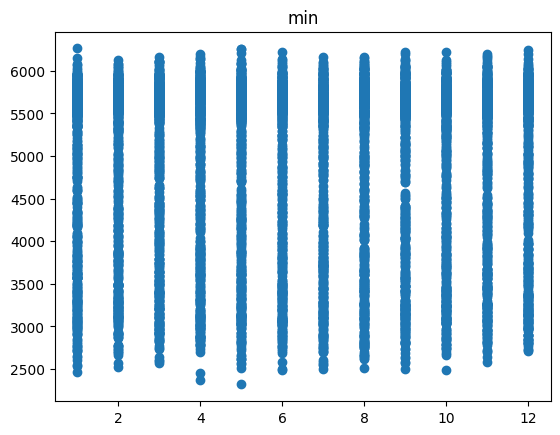

In [10]:
for i in data1.columns.drop('sm'):
  ypoints = data1['sm']
  plt.scatter(data1[i], ypoints)
  plt.title(i)
  plt.show()

In [11]:
data2['ttime']=pd.to_datetime(data2.ttime, format='%Y-%m-%d %H:%M:%S')
data2.set_index('ttime',inplace=True)
data2['day']=data2.index.day
data2['Month']=data2.index.month
data2['year']=data2.index.year
data2['hour']=data2.index.hour
data2['min']=(data2.index.minute//5)+1
data2.reset_index(inplace=True)
data2=data2.drop(['ttime'], axis=1)
data2

,pm1,pm2,pm3,am,sm,lum,temp,humd,pres,day,Month,year,hour,min
0,1.530287,2.829973,66.013473,0.046249,5482.503651,9.138662,18.745071,87.543675,93384.962812,18,7,2022,0,1
1,1.819614,3.683659,60.966552,1.748742,5628.854819,47.365276,17.792604,89.476277,92774.203811,18,7,2022,0,2
2,1.678294,4.667788,54.817035,0.867783,5434.584234,0.124629,18.971533,88.231759,93084.440989,18,7,2022,0,3
3,2.770304,2.589747,41.299593,1.843684,5547.269207,31.831347,20.284545,89.808017,93141.667995,18,7,2022,0,4
4,2.394154,2.118629,49.127881,0.962695,5602.309998,20.504264,17.648770,91.143399,93153.181732,18,7,2022,0,5
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
5995,1.701584,4.035324,59.623016,2.477149,5483.295281,37.833142,18.257204,87.275226,93346.990021,7,8,2022,19,8
5996,0.599019,2.794206,46.857064,1.619325,5460.653493,45.141333,NaN,NaN,NaN,7,8,2022,19,9
5997,0.684738,1.648355,43.648989,0.333698,5881.795913,0.233509,NaN,NaN,NaN,7,8,2022,19,10
5998,0.931051,2.077969,58.368029,4.747320,5673.677098,27.633877,NaN,NaN,NaN,7,8,2022,19,11


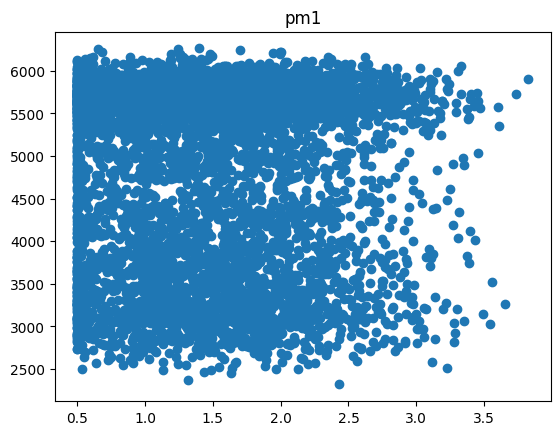

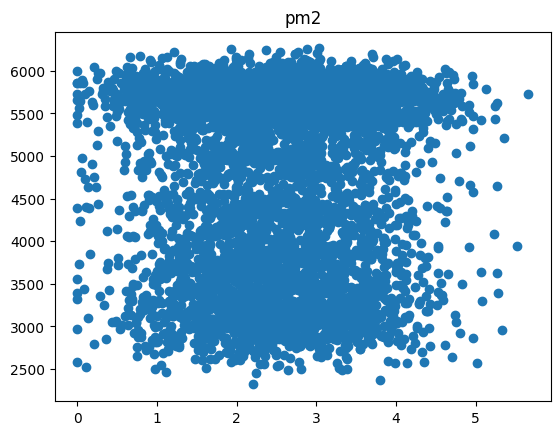

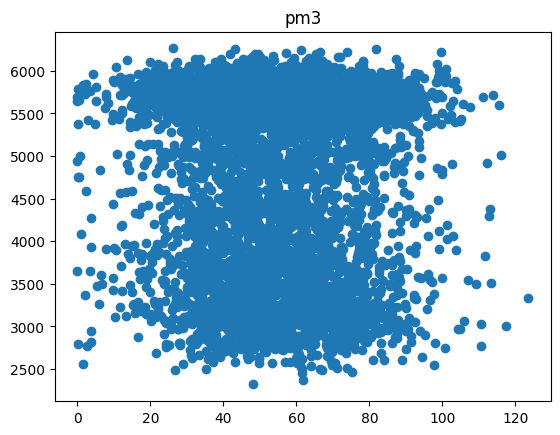

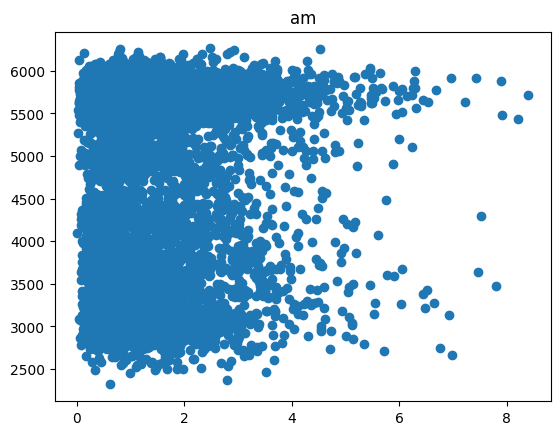

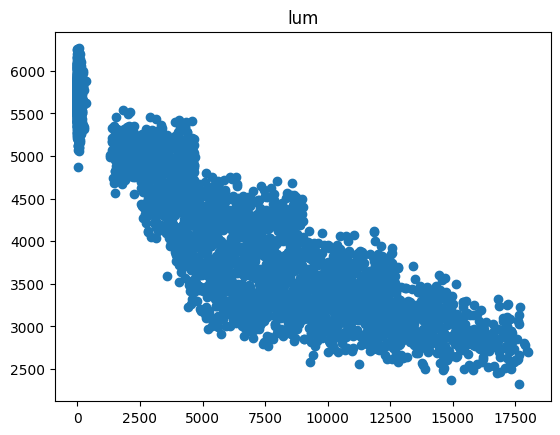

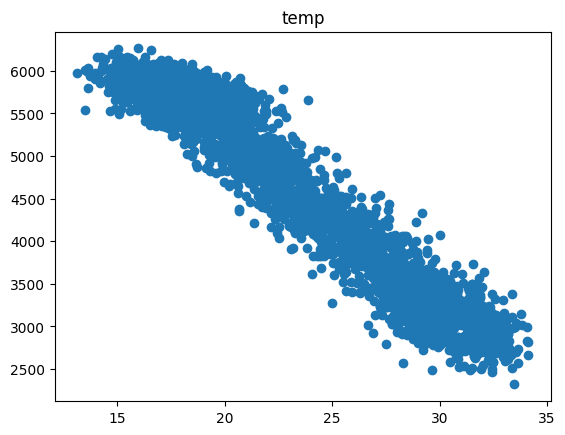

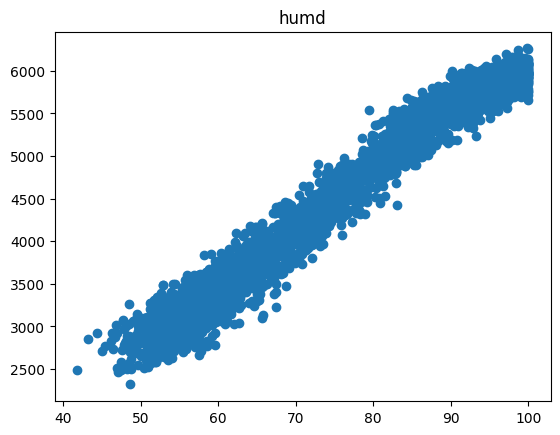

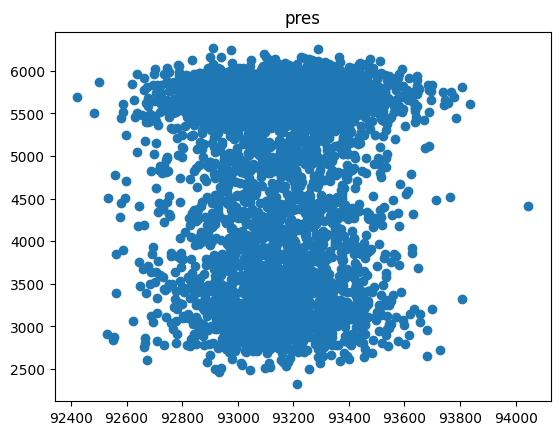

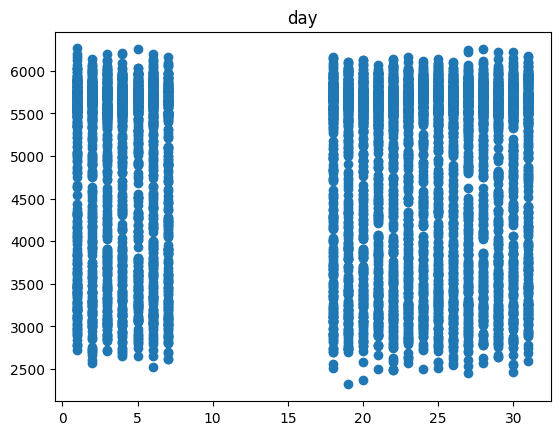

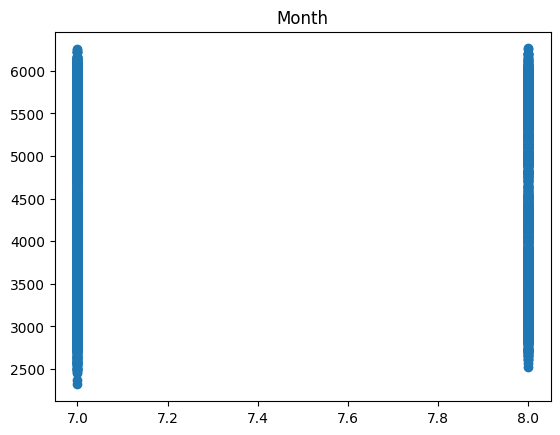

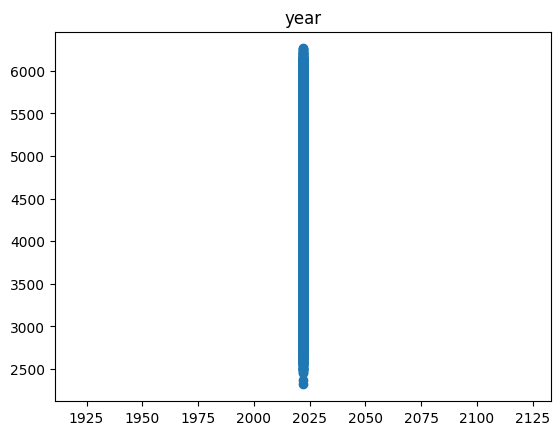

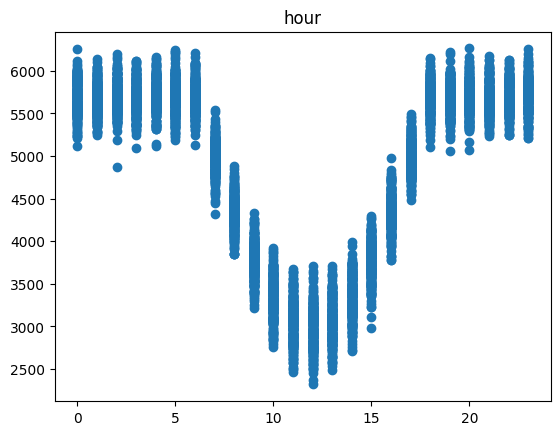

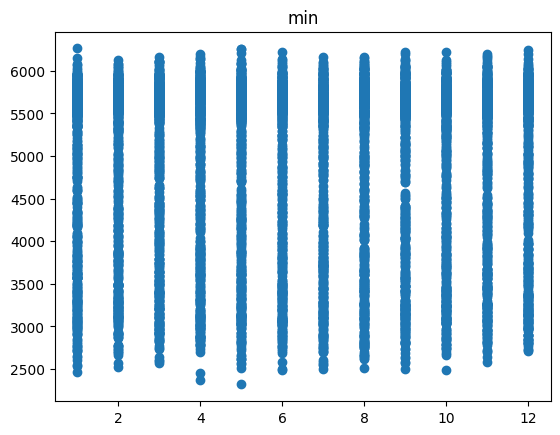

In [12]:
for i in data2.columns.drop('sm'):
  ypoints = data2['sm']
  plt.scatter( data2[i],ypoints)
  plt.title(i)
  plt.show()

#Combine Data

In [13]:
data_comb = data1.merge( data2, on=['day','Month','year','hour','min'], how='outer')
data_comb

,pm1_x,pm2_x,pm3_x,am_x,sm_x,st,lum_x,day,Month,year,...,min,pm1_y,pm2_y,pm3_y,am_y,sm_y,lum_y,temp,humd,pres
0,1.255741,2.623723,10.835585,4.590448,5887.968348,23.737931,40.546946,1,8,2022,...,1,1.212999,2.714863,11.017855,4.590448,5887.968348,40.546946,16.273269,94.017460,93015.556225
1,1.713516,4.217699,42.353278,1.908528,5943.387868,23.321349,23.190221,1,8,2022,...,2,1.685343,4.189298,41.855233,1.908528,5943.387868,23.190221,13.741382,89.834804,93401.135505
2,0.938109,1.122507,53.893991,1.190521,5515.155804,NaN,50.403808,1,8,2022,...,3,0.997835,1.205227,54.282732,1.190521,5515.155804,50.403808,16.785929,84.092714,93037.386760
3,1.730248,1.990896,87.394011,0.681009,5387.004636,23.548770,69.622413,1,8,2022,...,4,1.697140,1.989690,87.465113,0.681009,5387.004636,69.622413,19.435055,90.019140,93374.428347
4,2.187490,1.801309,84.061292,3.950072,5628.024689,NaN,35.714327,1,8,2022,...,5,2.074986,1.820272,84.898584,3.950072,5628.024689,35.714327,18.775420,90.782621,93244.920785
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
5995,1.581216,2.845048,71.042982,0.767633,5635.191507,24.366599,24.527196,31,7,2022,...,8,1.591890,2.942701,70.553546,0.767633,5635.191507,24.527196,17.610300,90.979251,93052.244591
5996,0.500000,3.489324,57.673295,3.784743,5301.492714,NaN,86.598493,31,7,2022,...,9,0.577829,3.513734,59.080790,3.784743,5301.492714,86.598493,NaN,NaN,NaN
5997,1.212999,2.499887,51.632418,3.824857,5691.161298,24.237160,8.349676,31,7,2022,...,10,1.197678,2.468014,51.923421,3.824857,5691.161298,8.349676,19.203193,91.667466,93443.262361
5998,1.420857,1.964235,69.743651,1.920973,5736.082313,24.245177,33.634274,31,7,2022,...,11,1.458044,1.889653,71.458673,1.920973,5736.082313,33.634274,19.293335,95.293693,93276.613309


In [14]:
# data_comb.columns
print('Count of missing values:\n',data_comb.shape[0]-data_comb.count())

Count of missing values:
 pm1_x       0
pm2_x       0
pm3_x       0
am_x        0
sm_x        0
st       2073
lum_x       0
day         0
Month       0
year        0
hour        0
min         0
pm1_y       0
pm2_y       0
pm3_y       0
am_y        0
sm_y        0
lum_y       0
temp     1744
humd     1744
pres     1744
dtype: int64


In [15]:
data_comb['pm1'] = data_comb[['pm1_x','pm1_y']].mean(axis=1)
data_comb['pm2'] = data_comb[['pm2_x','pm2_y']].mean(axis=1)
data_comb['pm3'] = data_comb[['pm3_x','pm3_y']].mean(axis=1)
data_comb['am'] = data_comb[['am_x','am_y']].mean(axis=1)
data_comb['sm'] = data_comb[['sm_x','sm_y']].mean(axis=1)
data_comb['lum'] = data_comb[['lum_x','lum_y']].mean(axis=1)
data_comb = data_comb.drop(['pm1_x','pm1_y','pm2_x','pm2_y','pm3_x','pm3_y','am_x','am_y','sm_x','sm_y','lum_x','lum_y'], axis=1)

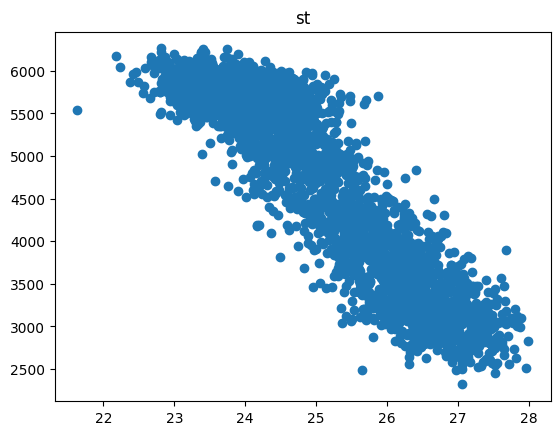

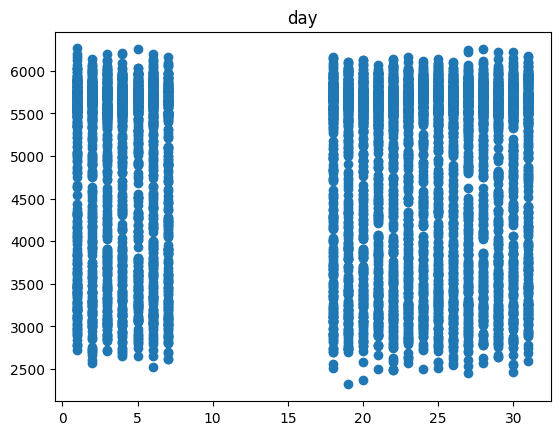

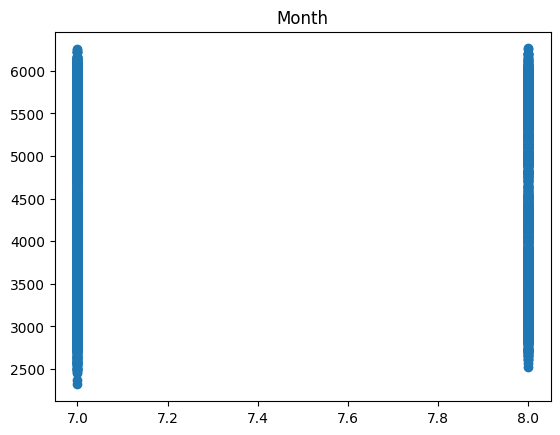

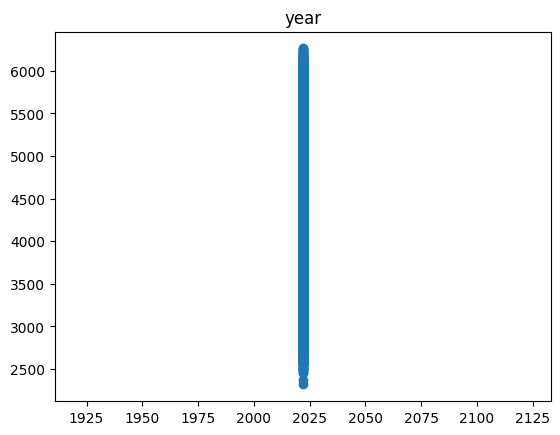

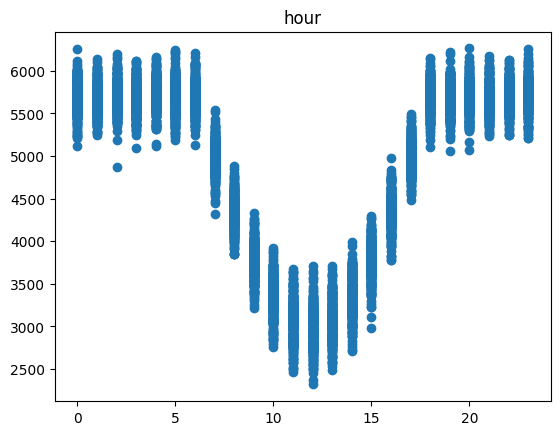

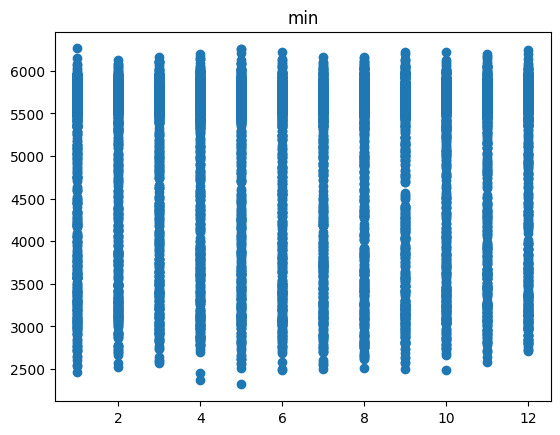

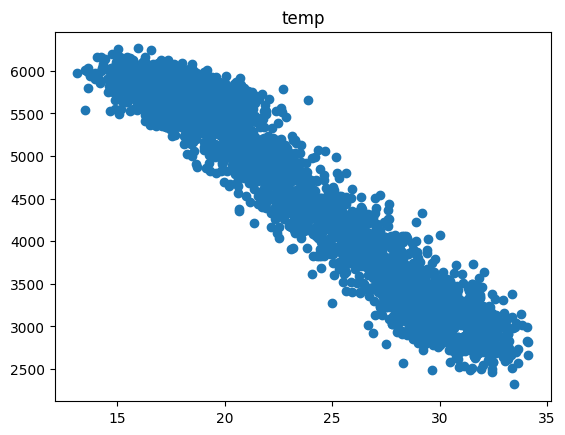

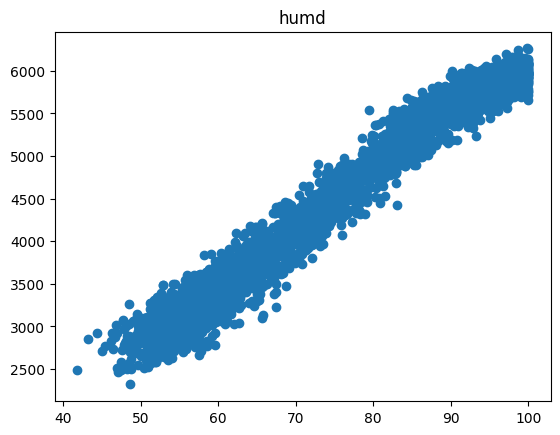

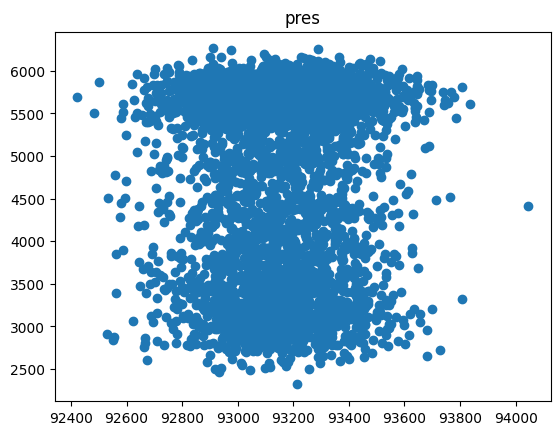

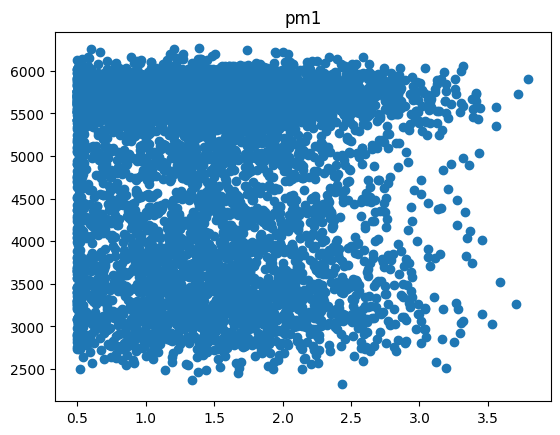

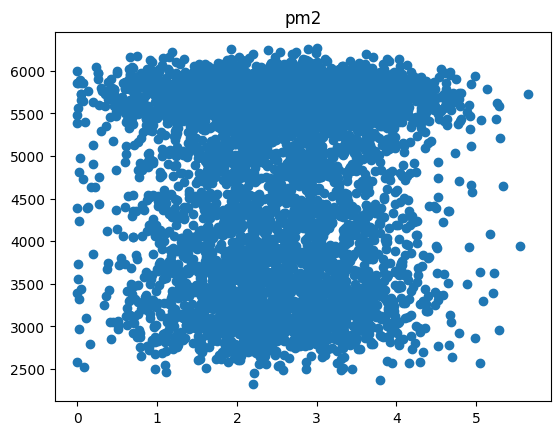

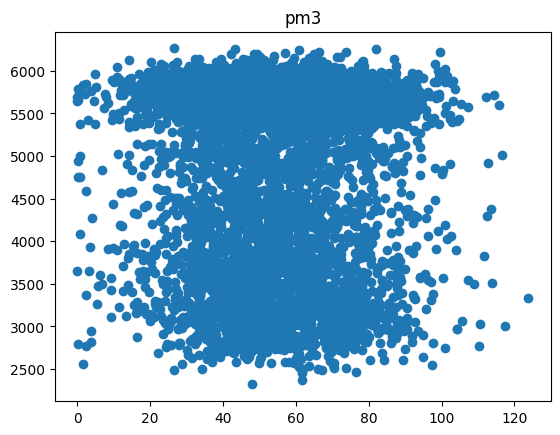

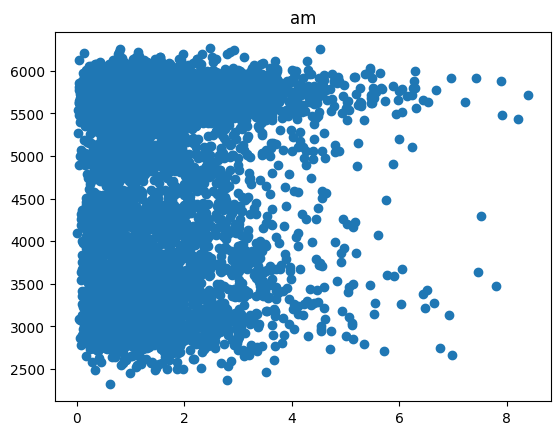

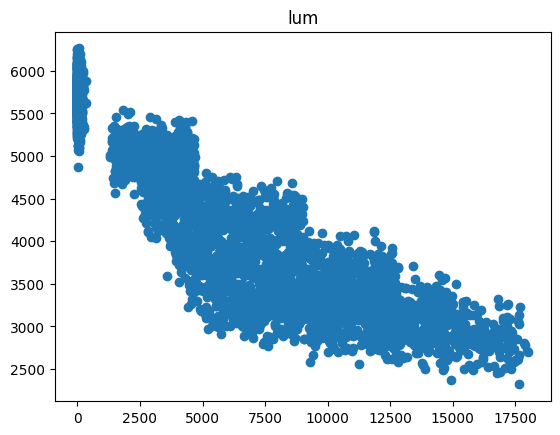

In [16]:
for i in data_comb.columns.drop('sm'):
  ypoints = data_comb['sm']
  plt.scatter(data_comb[i], ypoints)
  plt.title(i)
  plt.show()

In [17]:
data_comb.isnull().sum()

,0
st,2073
day,0
Month,0
year,0
hour,0
min,0
temp,1744
humd,1744
pres,1744
pm1,0


In [18]:
data_comb_path = '/content/data_comb.csv' if os.path.exists('/content') else 'data_comb.csv'
data_comb.to_csv(data_comb_path, index=False)
print('Đã lưu data_comb thành công vào:', data_comb_path)
data_comb.describe()

Đã lưu data_comb thành công vào: /content/data_comb.csv


,st,day,Month,year,hour,min,temp,humd,pres,pm1,pm2,pm3,am,sm,lum
count,3927.000000,6000.000000,6000.000000,6000.0,6000.000000,6000.00000,4256.000000,4256.000000,4256.000000,6000.000000,6000.000000,6000.000000,6000.000000,6000.000000,6000.000000
mean,24.897969,17.752000,7.328000,2022.0,11.420000,6.50000,22.149523,79.775569,93153.127573,1.521098,2.511181,55.024025,1.595622,4826.710128,3697.760530
std,1.221554,10.271323,0.469524,0.0,6.891409,3.45234,5.241504,15.231645,201.834704,0.647319,0.913716,18.150338,1.136769,1067.959005,4810.712423
min,21.632531,1.000000,7.000000,2022.0,0.000000,1.00000,13.138099,41.821374,92422.959954,0.500000,0.000000,0.000000,0.007642,2317.810448,0.000221
25%,23.933113,6.000000,7.000000,2022.0,5.000000,3.75000,17.878252,65.305378,93015.917392,1.020881,1.894708,42.817048,0.751245,3791.633788,24.613087
50%,24.564001,21.000000,7.000000,2022.0,11.000000,6.50000,20.022809,86.542621,93154.733151,1.493769,2.523687,55.329239,1.330010,5415.397925,102.915204
75%,25.938359,26.000000,8.000000,2022.0,17.000000,9.25000,27.156508,92.325123,93290.232462,1.964433,3.127135,67.050332,2.156423,5706.497088,6916.448522
max,27.995524,31.000000,8.000000,2022.0,23.000000,12.00000,34.129071,100.000000,94045.816850,3.796122,5.654082,123.791775,8.400750,6261.608197,18014.049705


#Model Runn Prep

In [19]:
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error,mean_absolute_error,r2_score
from sklearn.ensemble import RandomForestRegressor


In [20]:
data_comb_path = '/content/data_comb.csv' if os.path.exists('/content') else 'data_comb.csv'
if os.path.exists(data_comb_path):
    df1 = pd.read_csv(data_comb_path)
else:
    df1 = data_comb.copy()
# df1=df1.drop(['temp' ,'humd','st', 'pres'],axis=1)

In [21]:
df1.head()

,st,day,Month,year,hour,min,temp,humd,pres,pm1,pm2,pm3,am,sm,lum
0,23.737931,1,8,2022,0,1,16.273269,94.017460,93015.556225,1.234370,2.669293,10.926720,4.590448,5887.968348,40.546946
1,23.321349,1,8,2022,0,2,13.741382,89.834804,93401.135505,1.699429,4.203499,42.104255,1.908528,5943.387868,23.190221
2,NaN,1,8,2022,0,3,16.785929,84.092714,93037.386760,0.967972,1.163867,54.088361,1.190521,5515.155804,50.403808
3,23.548770,1,8,2022,0,4,19.435055,90.019140,93374.428347,1.713694,1.990293,87.429562,0.681009,5387.004636,69.622413
4,NaN,1,8,2022,0,5,18.775420,90.782621,93244.920785,2.131238,1.810791,84.479938,3.950072,5628.024689,35.714327


In [22]:
df1.isnull().sum()

,0
st,2073
day,0
Month,0
year,0
hour,0
min,0
temp,1744
humd,1744
pres,1744
pm1,0


In [23]:
if 'Unnamed: 0' in df1.columns:
    df1 = df1.drop('Unnamed: 0', axis=1)
X=df1.drop('sm',axis=1)
y=df1['sm']

# Random Forest Regressor

In [24]:
def rfr_score_dataset(X_train, X_test, y_train, y_test):
  forest = RandomForestRegressor(n_estimators=1000,
                                criterion='squared_error',
                                random_state=1,
                                n_jobs=-1)
  forest.fit(X_train, y_train)
  y_test_pred = forest.predict(X_test)

  print("MSE : ",(mean_squared_error(y_test, y_test_pred)))
  print("MAE : ",mean_absolute_error(y_test, y_test_pred))
  print('score:', forest.score(X_test, y_test))
  print("R square : ",r2_score(y_test, y_test_pred, force_finite=False))

# # for t in range(5,9,1) :
#   # for r in range(0,100,20) :
# X_train, X_valid, y_train, y_valid = train_test_split(X, y, train_size=80, test_size=20,random_state=32)
# print("train size : 80  random state : 32")
# print(rfr_score_dataset( X_train, X_valid, y_train, y_valid))

##RFR Imputation
 * use of Imputation method to clean Null Values

In [25]:
from sklearn.impute import SimpleImputer

X_train, X_valid, y_train, y_valid = train_test_split(X, y, train_size=0.8, test_size=0.2,random_state=32)


# Imputation
my_imputer = SimpleImputer()
imputed_X_train = pd.DataFrame(my_imputer.fit_transform(X_train))
imputed_X_valid = pd.DataFrame(my_imputer.transform(X_valid))

# Imputation removed column names; put them back
imputed_X_train.columns = X_train.columns
imputed_X_valid.columns = X_valid.columns

print("MAE from Approach 2 (Imputation):")
print(rfr_score_dataset(imputed_X_train, imputed_X_valid, y_train, y_valid))

MAE from Approach 2 (Imputation):
MSE :  18787.204369878276
MAE :  93.55303411014724
score: 0.9837201931050703
R square :  0.9837201931050703
None


* MAE : 93.55303411014724
* score: 0.9837201931050703

In [26]:
#train size : 80% random state : 60
# MSE :  3203.7463507195666
# score: 0.9996242501807985

##RFR An Extension to Imputation

*   use of Imputation method to clean Null Values
*   And column is Added to classify Changed value



In [27]:
# Make copy to avoid changing original data (when imputing)
X_train_plus = X_train.copy()
X_valid_plus = X_valid.copy()


cols_with_missing = [col for col in X_train.columns
                     if X_train[col].isnull().any()]
# Make new columns indicating what will be imputed
for col in cols_with_missing:
    X_train_plus[col + '_was_missing'] = X_train_plus[col].isnull()
    X_valid_plus[col + '_was_missing'] = X_valid_plus[col].isnull()
# Imputation
my_imputer = SimpleImputer()
imputed_X_train_plus = pd.DataFrame(my_imputer.fit_transform(X_train_plus))
imputed_X_valid_plus = pd.DataFrame(my_imputer.transform(X_valid_plus))

# Imputation removed column names; put them back
imputed_X_train_plus.columns = X_train_plus.columns
imputed_X_valid_plus.columns = X_valid_plus.columns

print("MAE from Approach 3 (An Extension to Imputation):")
print(rfr_score_dataset(imputed_X_train_plus, imputed_X_valid_plus, y_train, y_valid))

MAE from Approach 3 (An Extension to Imputation):
MSE :  18361.111246560675
MAE :  92.5293753306859
score: 0.9840894185433154
R square :  0.9840894185433154
None


* MAE : 92.5293753306859
* score: 0.9840894185433154

#RFR Pipeline

In [28]:
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import cross_val_score


## RFR pipeline Imputation

In [29]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.metrics import mean_absolute_error
X_train, X_valid, y_train, y_valid = train_test_split(X, y, train_size=0.8, test_size=0.2,random_state=32)

# Imputation
my_imputer = SimpleImputer()
imputed_X_train = pd.DataFrame(my_imputer.fit_transform(X_train))
imputed_X_valid = pd.DataFrame(my_imputer.transform(X_valid))

# Imputation removed column names; put them back
imputed_X_train.columns = X_train.columns
imputed_X_valid.columns = X_valid.columns

# Bundle preprocessing and modeling code in a pipeline
my_pipeline = Pipeline(steps=[('preprocessor', SimpleImputer(strategy="mean")),
                              ('model', RandomForestRegressor(n_estimators=1000, random_state=32))
                             ])

# Preprocessing of training data, fit model
my_pipeline.fit(imputed_X_train, y_train)

# Preprocessing of validation data, get predictions
preds = my_pipeline.predict(imputed_X_valid)

# Evaluate the model
score = mean_absolute_error(y_valid, preds)
print('MAE:', score)
print(my_pipeline.score(imputed_X_valid, y_valid))

MAE: 93.2375021996717
0.98381662855209


##RFR pipeline An Extension to Imputation

In [30]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.metrics import mean_absolute_error
X_train, X_valid, y_train, y_valid = train_test_split(X, y, train_size=0.8, test_size=0.2,random_state=32)

X_train_plus = X_train.copy()
X_valid_plus = X_valid.copy()


cols_with_missing = [col for col in X_train.columns
                     if X_train[col].isnull().any()]
# Make new columns indicating what will be imputed
for col in cols_with_missing:
    X_train_plus[col + '_was_missing'] = X_train_plus[col].isnull()
    X_valid_plus[col + '_was_missing'] = X_valid_plus[col].isnull()
# Imputation
my_imputer = SimpleImputer()
imputed_X_train_plus = pd.DataFrame(my_imputer.fit_transform(X_train_plus))
imputed_X_valid_plus = pd.DataFrame(my_imputer.transform(X_valid_plus))

# Imputation removed column names; put them back
imputed_X_train_plus.columns = X_train_plus.columns
imputed_X_valid_plus.columns = X_valid_plus.columns

# Preprocessing of training data, fit model
my_pipeline.fit(imputed_X_train_plus, y_train)

# Preprocessing of validation data, get predictions
preds = my_pipeline.predict(imputed_X_valid_plus)

# Evaluate the model
score = mean_absolute_error(y_valid, preds)
print('MAE:', score)
print(my_pipeline.score(imputed_X_valid_plus, y_valid))

MAE: 92.3988078247279
0.9841278289193467


#XG Boost


 ## XG Boost Imputation

In [32]:
from xgboost import XGBRegressor
X_train, X_valid, y_train, y_valid = train_test_split(X, y, train_size=0.8, test_size=0.2,random_state=32)

# Imputation
my_imputer = SimpleImputer()
imputed_X_train = pd.DataFrame(my_imputer.fit_transform(X_train))
imputed_X_valid = pd.DataFrame(my_imputer.transform(X_valid))

# Imputation removed column names; put them back
imputed_X_train.columns = X_train.columns
imputed_X_valid.columns = X_valid.columns

my_model1 = XGBRegressor(n_estimators=1000, learning_rate=0.05, n_jobs=4, early_stopping_rounds=5)
my_model1.fit(imputed_X_train, y_train,
              eval_set=[(imputed_X_valid, y_valid)],
              verbose=False)


XGBRegressor(base_score=None, booster=None, callbacks=None,
             colsample_bylevel=None, colsample_bynode=None,
             colsample_bytree=None, device=None, early_stopping_rounds=5,
             enable_categorical=True, eval_metric=None, feature_types=None,
             feature_weights=None, gamma=None, grow_policy=None,
             importance_type=None, interaction_constraints=None,
             learning_rate=0.05, max_bin=None, max_cat_threshold=None,
             max_cat_to_onehot=None, max_delta_step=None, max_depth=None,
             max_leaves=None, min_child_weight=None, missing=nan,
             monotone_constraints=None, multi_strategy=None, n_estimators=1000,
             n_jobs=4, num_parallel_tree=None, ...)

In [33]:
preds = my_model1.predict(imputed_X_valid)
print(mean_absolute_error(y_valid, preds))
print(my_model1.score(imputed_X_valid, y_valid))

93.05986473646013
0.9843184513377949


## XG Boost An Extension to Imputation




In [34]:
X_train, X_valid, y_train, y_valid = train_test_split(X, y, train_size=0.8, test_size=0.2,random_state=32)

X_train_plus = X_train.copy()
X_valid_plus = X_valid.copy()


cols_with_missing = [col for col in X_train.columns
                     if X_train[col].isnull().any()]
# Make new columns indicating what will be imputed
for col in cols_with_missing:
    X_train_plus[col + '_was_missing'] = X_train_plus[col].isnull()
    X_valid_plus[col + '_was_missing'] = X_valid_plus[col].isnull()
# Imputation
my_imputer = SimpleImputer()
imputed_X_train_plus = pd.DataFrame(my_imputer.fit_transform(X_train_plus))
imputed_X_valid_plus = pd.DataFrame(my_imputer.transform(X_valid_plus))

# Imputation removed column names; put them back
imputed_X_train_plus.columns = X_train_plus.columns
imputed_X_valid_plus.columns = X_valid_plus.columns

my_model = XGBRegressor(n_estimators=1000, learning_rate=0.05, n_jobs=4, early_stopping_rounds=5)
my_model.fit(imputed_X_train_plus, y_train,
             eval_set=[(imputed_X_valid_plus, y_valid)],
             verbose=False)

XGBRegressor(base_score=None, booster=None, callbacks=None,
             colsample_bylevel=None, colsample_bynode=None,
             colsample_bytree=None, device=None, early_stopping_rounds=5,
             enable_categorical=True, eval_metric=None, feature_types=None,
             feature_weights=None, gamma=None, grow_policy=None,
             importance_type=None, interaction_constraints=None,
             learning_rate=0.05, max_bin=None, max_cat_threshold=None,
             max_cat_to_onehot=None, max_delta_step=None, max_depth=None,
             max_leaves=None, min_child_weight=None, missing=nan,
             monotone_constraints=None, multi_strategy=None, n_estimators=1000,
             n_jobs=4, num_parallel_tree=None, ...)

In [35]:
preds = my_model.predict(imputed_X_valid_plus)
print(mean_absolute_error(y_valid, preds))
print(my_model.score(imputed_X_valid_plus, y_valid))

92.1311442363794
0.9842758259335969


In [36]:
# 44.41299256285513
# 99.92987124951946

# MAE: 36.268992130750604
# 99.94174852973395

# RESULT (comparing all result)

****
****
***Random Forest Regressor***
****
****
**RFR Imputation**
* MAE : 93.55303411014724
* score: 0.9837201931050703
*****
**RFR An Extension to Imputation**
* MAE : 92.5293753306859
* score: 0.9840894185433154
****
****
***RFR Pipeline***
****
****
**RFR Pipeline Imputation**
* MAE: 93.2375021996717
* score: 0.98381662855209
****
**RFR Pipeline An Extension to Imputation**
* MAE: 92.3988078247279
* score: 0.9841278289193467
****
****
***XG Boost***
****
****
**XG Boost Imputation**
* MAE: 93.05986473646013
* score: 0.9843184513377949
****
**XG Boost An Extension to Imputation**
* MAE: 92.1311442363794
* score: 0.9842758259335969
****
****

# BEST MODEL

In [37]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.metrics import mean_absolute_error
X_train, X_valid, y_train, y_valid = train_test_split(X, y, train_size=0.8, test_size=0.2,random_state=32)

X_train_plus = X_train.copy()
X_valid_plus = X_valid.copy()


cols_with_missing = [col for col in X_train.columns
                     if X_train[col].isnull().any()]
# Make new columns indicating what will be imputed
for col in cols_with_missing:
    X_train_plus[col + '_was_missing'] = X_train_plus[col].isnull()
    X_valid_plus[col + '_was_missing'] = X_valid_plus[col].isnull()
# Imputation
my_imputer = SimpleImputer()
imputed_X_train_plus = pd.DataFrame(my_imputer.fit_transform(X_train_plus))
imputed_X_valid_plus = pd.DataFrame(my_imputer.transform(X_valid_plus))

# Imputation removed column names; put them back
imputed_X_train_plus.columns = X_train_plus.columns
imputed_X_valid_plus.columns = X_valid_plus.columns

# Bundle preprocessing and modeling code in a pipeline
my_pipeline = Pipeline(steps=[('preprocessor', SimpleImputer(strategy="mean")),
                              ('model', RandomForestRegressor(n_estimators=1000, random_state=32))
                             ])

# Preprocessing of training data, fit model
my_pipeline.fit(imputed_X_train_plus, y_train)

# Preprocessing of validation data, get predictions
preds = my_pipeline.predict(imputed_X_valid_plus)

# Evaluate the model
score = mean_absolute_error(y_valid, preds)
print('MAE:', score)
print(my_pipeline.score(imputed_X_valid_plus, y_valid))

MAE: 92.3988078247279
0.9841278289193467


# Đánh giá chi tiết & Trực quan hóa kết quả (Evaluation & Visualization)
* So sánh giá trị độ ẩm thực tế (**Actual Soil Moisture**) và giá trị mô hình dự đoán (**Predicted Soil Moisture**).
* Đánh giá độ quan trọng của từng đặc trưng (**Feature Importances**) để xác định các yếu tố môi trường chi phối mạnh nhất đến độ ẩm đất.

--- KẾT QUẢ ĐÁNH GIÁ MÔ HÌNH TỐT NHẤT ---
MAE  (Mean Absolute Error)     : 92.40
MSE  (Mean Squared Error)      : 18316.78
RMSE (Root Mean Squared Error) : 135.34
R² Score (Hệ số xác định R2)   : 0.9841


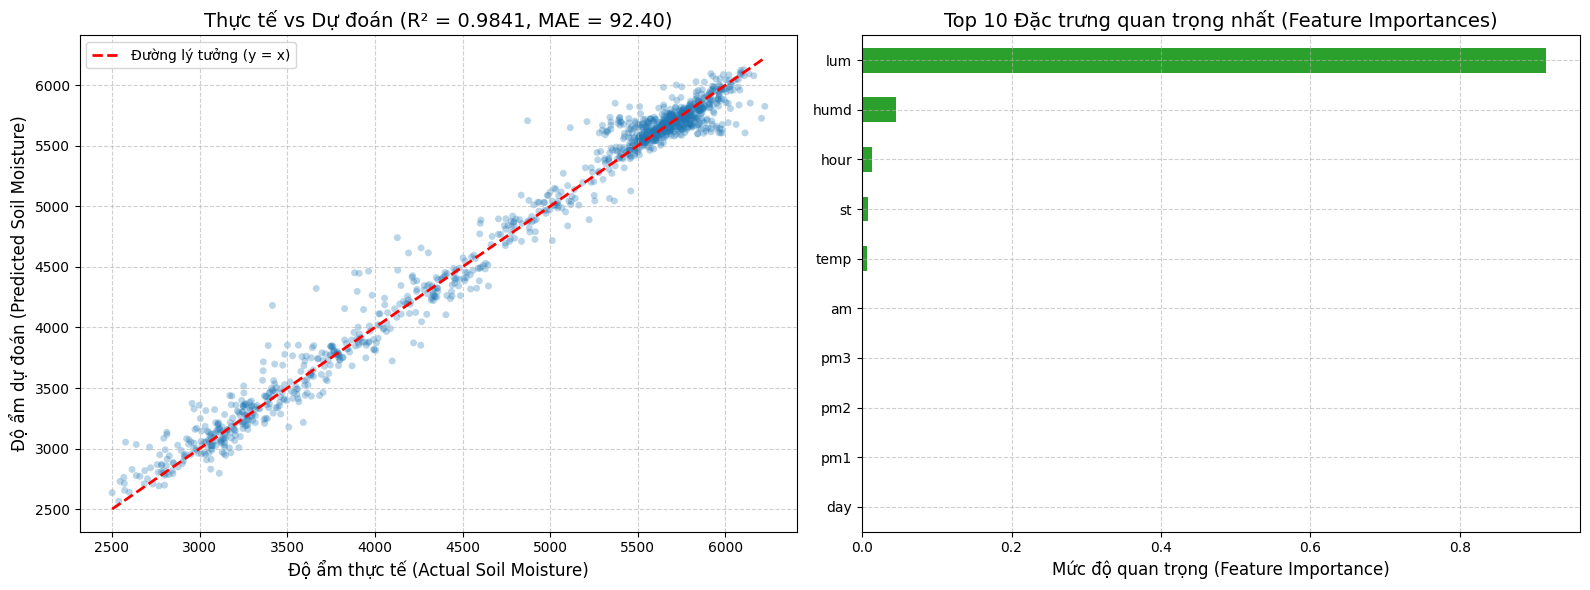

In [38]:
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

# Tính toán các chỉ số đánh giá chi tiết
mae_val = mean_absolute_error(y_valid, preds)
mse_val = mean_squared_error(y_valid, preds)
rmse_val = np.sqrt(mse_val)
r2_val = r2_score(y_valid, preds)

print('='*45)
print('--- KẾT QUẢ ĐÁNH GIÁ MÔ HÌNH TỐT NHẤT ---')
print(f'MAE  (Mean Absolute Error)     : {mae_val:.2f}')
print(f'MSE  (Mean Squared Error)      : {mse_val:.2f}')
print(f'RMSE (Root Mean Squared Error) : {rmse_val:.2f}')
print(f'R² Score (Hệ số xác định R2)   : {r2_val:.4f}')
print('='*45)

# Trực quan hóa kết quả
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Biểu đồ 1: Thực tế vs Dự đoán
axes[0].scatter(y_valid, preds, alpha=0.3, color='#1f77b4', edgecolors='none', s=25)
min_val = min(y_valid.min(), preds.min())
max_val = max(y_valid.max(), preds.max())
axes[0].plot([min_val, max_val], [min_val, max_val], 'r--', lw=2, label='Đường lý tưởng (y = x)')
axes[0].set_xlabel('Độ ẩm thực tế (Actual Soil Moisture)', fontsize=12)
axes[0].set_ylabel('Độ ẩm dự đoán (Predicted Soil Moisture)', fontsize=12)
axes[0].set_title(f'Thực tế vs Dự đoán (R² = {r2_val:.4f}, MAE = {mae_val:.2f})', fontsize=14)
axes[0].legend()
axes[0].grid(True, linestyle='--', alpha=0.6)

# Biểu đồ 2: Độ quan trọng đặc trưng (Feature Importances)
best_rf = my_pipeline.named_steps['model']
importances = pd.Series(best_rf.feature_importances_, index=imputed_X_train_plus.columns)
top_features = importances.sort_values(ascending=False).head(10)

top_features.plot(kind='barh', ax=axes[1], color='#2ca02c')
axes[1].set_title('Top 10 Đặc trưng quan trọng nhất (Feature Importances)', fontsize=14)
axes[1].set_xlabel('Mức độ quan trọng (Feature Importance)', fontsize=12)
axes[1].invert_yaxis()
axes[1].grid(True, linestyle='--', alpha=0.6)

plt.tight_layout()
plt.show()